In [1]:
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

# Dataset paths
DATA_DIR = Path("../data")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Image configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Number of disease/healthy classes
NUM_CLASSES = 15

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

TensorFlow version: 2.21.0
Image size: (224, 224)
Batch size: 32
Number of classes: 15


In [2]:
# Load training dataset

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Load validation dataset

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Get class names
class_names = train_ds.class_names

print("\nNumber of classes:", len(class_names))
print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, "->", name)

Found 15474 files belonging to 15 classes.
Found 3310 files belonging to 15 classes.

Number of classes: 15

Classes:
0 -> Corn___Cercospora_leaf_spot Gray_leaf_spot
1 -> Corn___Common_rust
2 -> Corn___Northern_Leaf_Blight
3 -> Corn___healthy
4 -> Potato___Early_blight
5 -> Potato___Late_blight
6 -> Potato___healthy
7 -> Tomato___Bacterial_spot
8 -> Tomato___Early_blight
9 -> Tomato___Late_blight
10 -> Tomato___Leaf_Mold
11 -> Tomato___Septoria_leaf_spot
12 -> Tomato___Target_Spot
13 -> Tomato___Tomato_Yellow_Leaf_Curl_Virus
14 -> Tomato___healthy


In [3]:
# Data augmentation for MobileNetV2 training

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

print("Data augmentation created.")

Data augmentation created.


In [4]:
# MobileNetV2 preprocessing

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

print("MobileNetV2 preprocessing function ready.")

MobileNetV2 preprocessing function ready.


In [5]:
# Load pretrained MobileNetV2

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Total layers:", len(base_model.layers))
print("Base model trainable:", base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully.
Total layers: 154
Base model trainable: False


In [6]:
# Build the MobileNetV2 transfer-learning model

inputs = tf.keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = preprocess_input(x)

# Pretrained MobileNetV2
x = base_model(x, training=False)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

transfer_model = tf.keras.Model(
    inputs,
    outputs,
    name="MobileNetV2_CropDisease"
)

transfer_model.summary()

Model: "MobileNetV2_CropDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Compile the MobileNetV2 transfer-learning model

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 transfer-learning model compiled successfully.")

MobileNetV2 transfer-learning model compiled successfully.


In [8]:
# Callbacks for MobileNetV2 transfer learning

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

transfer_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "mobilenetv2_head_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("MobileNetV2 callbacks created.")
print(
    "Best model will be saved to:",
    MODEL_DIR / "mobilenetv2_head_best.keras"
)

MobileNetV2 callbacks created.
Best model will be saved to: ..\models\mobilenetv2_head_best.keras


In [9]:
# Prepare datasets for MobileNetV2 training

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Training dataset prepared.")
print("Validation dataset prepared.")
print("Augmentation and MobileNetV2 preprocessing are handled inside the model.")

Training dataset prepared.
Validation dataset prepared.
Augmentation and MobileNetV2 preprocessing are handled inside the model.


In [10]:
# Train MobileNetV2 with the pretrained base frozen

EPOCHS = 10

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=transfer_callbacks
)

print("MobileNetV2 frozen-base training completed.")

Epoch 1/10


c:\Agro Care Ai\Agro Care AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 976ms/step - accuracy: 0.7643 - loss: 0.7447
Epoch 1: val_loss improved from None to 0.39121, saving model to ..\models\mobilenetv2_head_best.keras

Epoch 1: finished saving model to ..\models\mobilenetv2_head_best.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 536s 1s/step - accuracy: 0.7643 - loss: 0.7447 - val_accuracy: 0.8737 - val_loss: 0.3912
Epoch 2/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 596ms/step - accuracy: 0.8743 - loss: 0.3891
Epoch 2: val_loss improved from 0.39121 to 0.31553, saving model to ..\models\mobilenetv2_head_best.keras

Epoch 2: finished saving model to ..\models\mobilenetv2_head_best.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 342s 707ms/step - accuracy: 0.8743 - loss: 0.3891 - val_accuracy: 0.8994 - val_loss: 0.3155
Epoch 3/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - accuracy: 0.8837 - loss: 0.3410
Epoch 3: val_loss improved from 0.31553 to 0.30281, saving model to ..\models\mobilenetv2_head_best.keras

Epoch 3: finished saving model to ..\models\mo

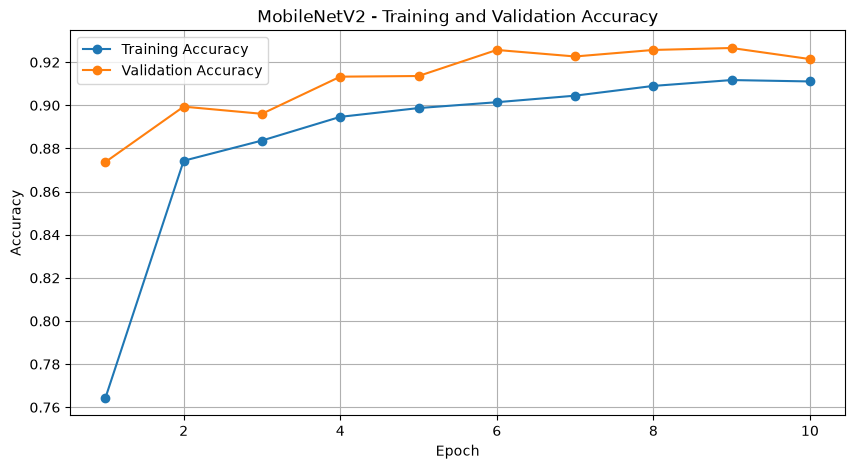

In [11]:
# Plot MobileNetV2 training and validation accuracy

transfer_train_acc = transfer_history.history["accuracy"]
transfer_val_acc = transfer_history.history["val_accuracy"]

transfer_epochs = range(1, len(transfer_train_acc) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    transfer_epochs,
    transfer_train_acc,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    transfer_epochs,
    transfer_val_acc,
    marker="o",
    label="Validation Accuracy"
)

plt.title("MobileNetV2 - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

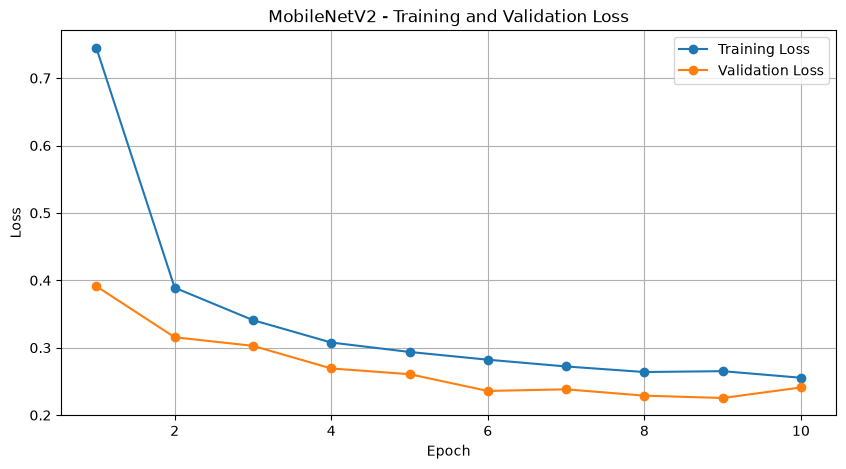

In [12]:
# Plot MobileNetV2 training and validation loss

transfer_train_loss = transfer_history.history["loss"]
transfer_val_loss = transfer_history.history["val_loss"]

plt.figure(figsize=(10, 5))

plt.plot(
    transfer_epochs,
    transfer_train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    transfer_epochs,
    transfer_val_loss,
    marker="o",
    label="Validation Loss"
)

plt.title("MobileNetV2 - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
# Load the best MobileNetV2 model

best_transfer_model = tf.keras.models.load_model(
    "../models/mobilenetv2_head_best.keras"
)

print("Best MobileNetV2 model loaded successfully.")

Best MobileNetV2 model loaded successfully.


In [15]:
# Load the test dataset for MobileNetV2 evaluation

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_class_names = test_ds.class_names

test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test dataset loaded successfully.")
print("Test images: 3331")
print("Test classes:", len(test_class_names))
print("Classes match:", test_class_names == class_names)

Found 3331 files belonging to 15 classes.
Test dataset loaded successfully.
Test images: 3331
Test classes: 15
Classes match: True


In [16]:
# Generate MobileNetV2 predictions on the test set

transfer_y_true = []
transfer_y_pred = []

for images, labels in test_ds:
    predictions = best_transfer_model.predict(images, verbose=0)

    predicted_classes = tf.argmax(
        predictions,
        axis=1
    ).numpy()

    transfer_y_true.extend(labels.numpy())
    transfer_y_pred.extend(predicted_classes)

print("MobileNetV2 predictions generated successfully.")
print("True labels:", len(transfer_y_true))
print("Predicted labels:", len(transfer_y_pred))

MobileNetV2 predictions generated successfully.
True labels: 3331
Predicted labels: 3331


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


In [19]:
# Calculate MobileNetV2 test metrics

transfer_test_accuracy = accuracy_score(
    transfer_y_true,
    transfer_y_pred
)

transfer_macro_precision = precision_score(
    transfer_y_true,
    transfer_y_pred,
    average="macro",
    zero_division=0
)

transfer_macro_recall = recall_score(
    transfer_y_true,
    transfer_y_pred,
    average="macro",
    zero_division=0
)

transfer_macro_f1 = f1_score(
    transfer_y_true,
    transfer_y_pred,
    average="macro",
    zero_division=0
)

print("MobileNetV2 Test Results")
print("=" * 40)
print(f"Test Accuracy   : {transfer_test_accuracy:.4f}")
print(f"Macro Precision : {transfer_macro_precision:.4f}")
print(f"Macro Recall    : {transfer_macro_recall:.4f}")
print(f"Macro F1 Score  : {transfer_macro_f1:.4f}")

MobileNetV2 Test Results
Test Accuracy   : 0.9255
Macro Precision : 0.9051
Macro Recall    : 0.9148
Macro F1 Score  : 0.9082


In [20]:
from sklearn.metrics import classification_report

transfer_report = classification_report(
    transfer_y_true,
    transfer_y_pred,
    target_names=test_class_names,
    digits=4
)

print("MobileNetV2 Classification Report")
print("=" * 60)
print(transfer_report)

MobileNetV2 Classification Report
                                            precision    recall  f1-score   support

Corn___Cercospora_leaf_spot Gray_leaf_spot     0.7625    0.7821    0.7722        78
                        Corn___Common_rust     0.9783    1.0000    0.9890       180
               Corn___Northern_Leaf_Blight     0.8844    0.8725    0.8784       149
                            Corn___healthy     1.0000    0.9943    0.9971       175
                     Potato___Early_blight     0.9801    0.9867    0.9834       150
                      Potato___Late_blight     0.8931    0.9467    0.9191       150
                          Potato___healthy     0.9231    1.0000    0.9600        24
                   Tomato___Bacterial_spot     0.9128    0.9156    0.9142       320
                     Tomato___Early_blight     0.8618    0.7067    0.7766       150
                      Tomato___Late_blight     0.9718    0.8397    0.9009       287
                        Tomato___Leaf_Mol

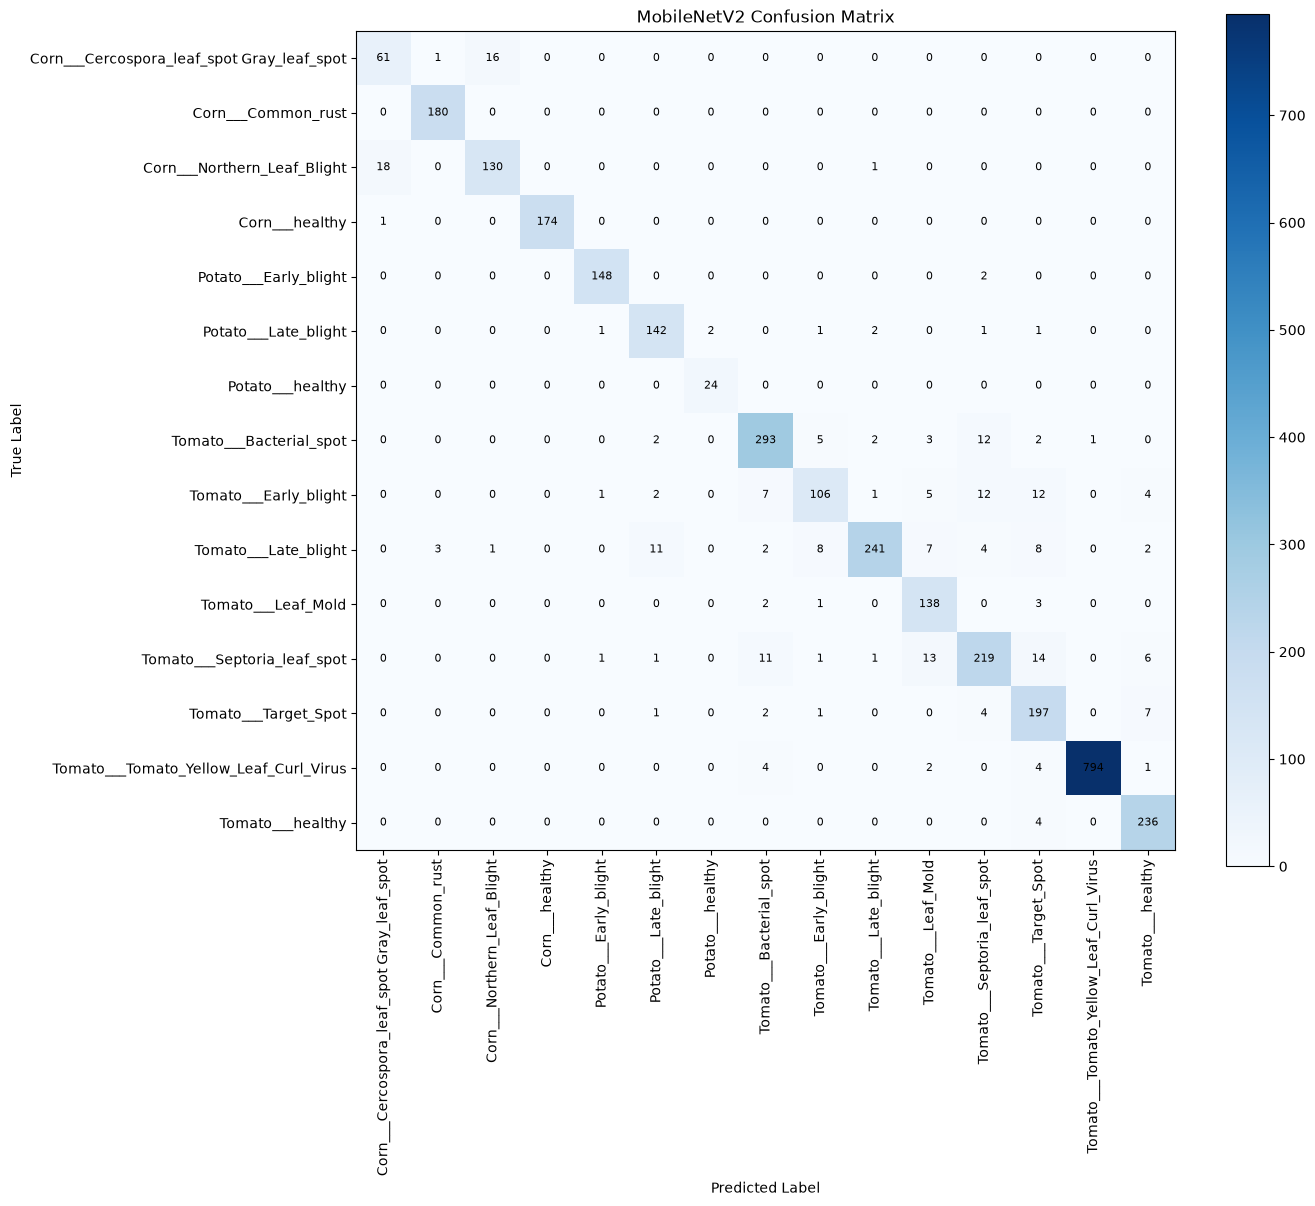

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

transfer_cm = confusion_matrix(
    transfer_y_true,
    transfer_y_pred
)

plt.figure(figsize=(14, 12))
plt.imshow(transfer_cm, cmap="Blues")
plt.colorbar()

plt.xticks(
    np.arange(len(test_class_names)),
    test_class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(test_class_names)),
    test_class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MobileNetV2 Confusion Matrix")

for i in range(len(test_class_names)):
    for j in range(len(test_class_names)):
        plt.text(
            j, i,
            transfer_cm[i, j],
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

In [22]:
# Prepare MobileNetV2 for fine-tuning

base_model.trainable = True

# Freeze all layers except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

trainable_layers = sum(
    layer.trainable for layer in base_model.layers
)

print("MobileNetV2 fine-tuning preparation complete.")
print("Trainable base-model layers:", trainable_layers)

MobileNetV2 fine-tuning preparation complete.
Trainable base-model layers: 19


In [23]:
# Recompile model for fine-tuning

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")
print("Learning rate: 1e-5")

Model recompiled for fine-tuning.
Learning rate: 1e-5


In [24]:
# Fine-tune MobileNetV2

fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/mobilenetv2_finetuned_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

fine_tune_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        fine_tune_checkpoint,
        fine_tune_early_stopping
    ]
)

Epoch 1/10


c:\Agro Care Ai\Agro Care AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.9223 - loss: 0.2227
Epoch 1: val_loss improved from None to 0.18701, saving model to ../models/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to ../models/mobilenetv2_finetuned_best.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 322s 649ms/step - accuracy: 0.9223 - loss: 0.2227 - val_accuracy: 0.9369 - val_loss: 0.1870
Epoch 2/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - accuracy: 0.9325 - loss: 0.1913
Epoch 2: val_loss improved from 0.18701 to 0.16326, saving model to ../models/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to ../models/mobilenetv2_finetuned_best.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 371s 767ms/step - accuracy: 0.9325 - loss: 0.1913 - val_accuracy: 0.9486 - val_loss: 0.1633
Epoch 3/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 681ms/step - accuracy: 0.9411 - loss: 0.1682
Epoch 3: val_loss did not improve from 0.16326
484/484 ━━━━━━━━━━━━━━━━━━━━ 385s 795ms/step - accuracy: 0.9411 - loss: 0.1682 - va

In [25]:
# Load the best fine-tuned model

fine_tuned_model = tf.keras.models.load_model(
    "../models/mobilenetv2_finetuned_best.keras"
)

print("Best fine-tuned model loaded successfully.")

Best fine-tuned model loaded successfully.


In [27]:
# Generate predictions using the fine-tuned model

fine_tuned_probs = fine_tuned_model.predict(
    test_ds,
    verbose=1
)

fine_tuned_y_pred = np.argmax(
    fine_tuned_probs,
    axis=1
)

print("Fine-tuned predictions generated.")
print("Number of predictions:", len(fine_tuned_y_pred))
print("Number of true labels:", len(transfer_y_true))

105/105 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step
Fine-tuned predictions generated.
Number of predictions: 3331
Number of true labels: 3331


In [28]:
# Evaluate fine-tuned MobileNetV2

fine_tuned_test_accuracy = accuracy_score(
    transfer_y_true,
    fine_tuned_y_pred
)

fine_tuned_macro_precision = precision_score(
    transfer_y_true,
    fine_tuned_y_pred,
    average="macro",
    zero_division=0
)

fine_tuned_macro_recall = recall_score(
    transfer_y_true,
    fine_tuned_y_pred,
    average="macro",
    zero_division=0
)

fine_tuned_macro_f1 = f1_score(
    transfer_y_true,
    fine_tuned_y_pred,
    average="macro",
    zero_division=0
)

print("Fine-Tuned MobileNetV2 Test Results")
print("=" * 45)
print(f"Test Accuracy   : {fine_tuned_test_accuracy:.4f}")
print(f"Macro Precision : {fine_tuned_macro_precision:.4f}")
print(f"Macro Recall    : {fine_tuned_macro_recall:.4f}")
print(f"Macro F1 Score  : {fine_tuned_macro_f1:.4f}")

Fine-Tuned MobileNetV2 Test Results
Test Accuracy   : 0.9589
Macro Precision : 0.9488
Macro Recall    : 0.9417
Macro F1 Score  : 0.9435


In [29]:
# Fine-tuned MobileNetV2 classification report

fine_tuned_report = classification_report(
    transfer_y_true,
    fine_tuned_y_pred,
    target_names=test_class_names,
    digits=4
)

print("Fine-Tuned MobileNetV2 Classification Report")
print("=" * 65)
print(fine_tuned_report)

Fine-Tuned MobileNetV2 Classification Report
                                            precision    recall  f1-score   support

Corn___Cercospora_leaf_spot Gray_leaf_spot     0.8710    0.6923    0.7714        78
                        Corn___Common_rust     0.9945    1.0000    0.9972       180
               Corn___Northern_Leaf_Blight     0.8537    0.9396    0.8946       149
                            Corn___healthy     1.0000    0.9943    0.9971       175
                     Potato___Early_blight     0.9933    0.9867    0.9900       150
                      Potato___Late_blight     0.9669    0.9733    0.9701       150
                          Potato___healthy     0.9600    1.0000    0.9796        24
                   Tomato___Bacterial_spot     0.9377    0.9875    0.9619       320
                     Tomato___Early_blight     0.9600    0.8000    0.8727       150
                      Tomato___Late_blight     0.9650    0.9617    0.9634       287
                        Tomato

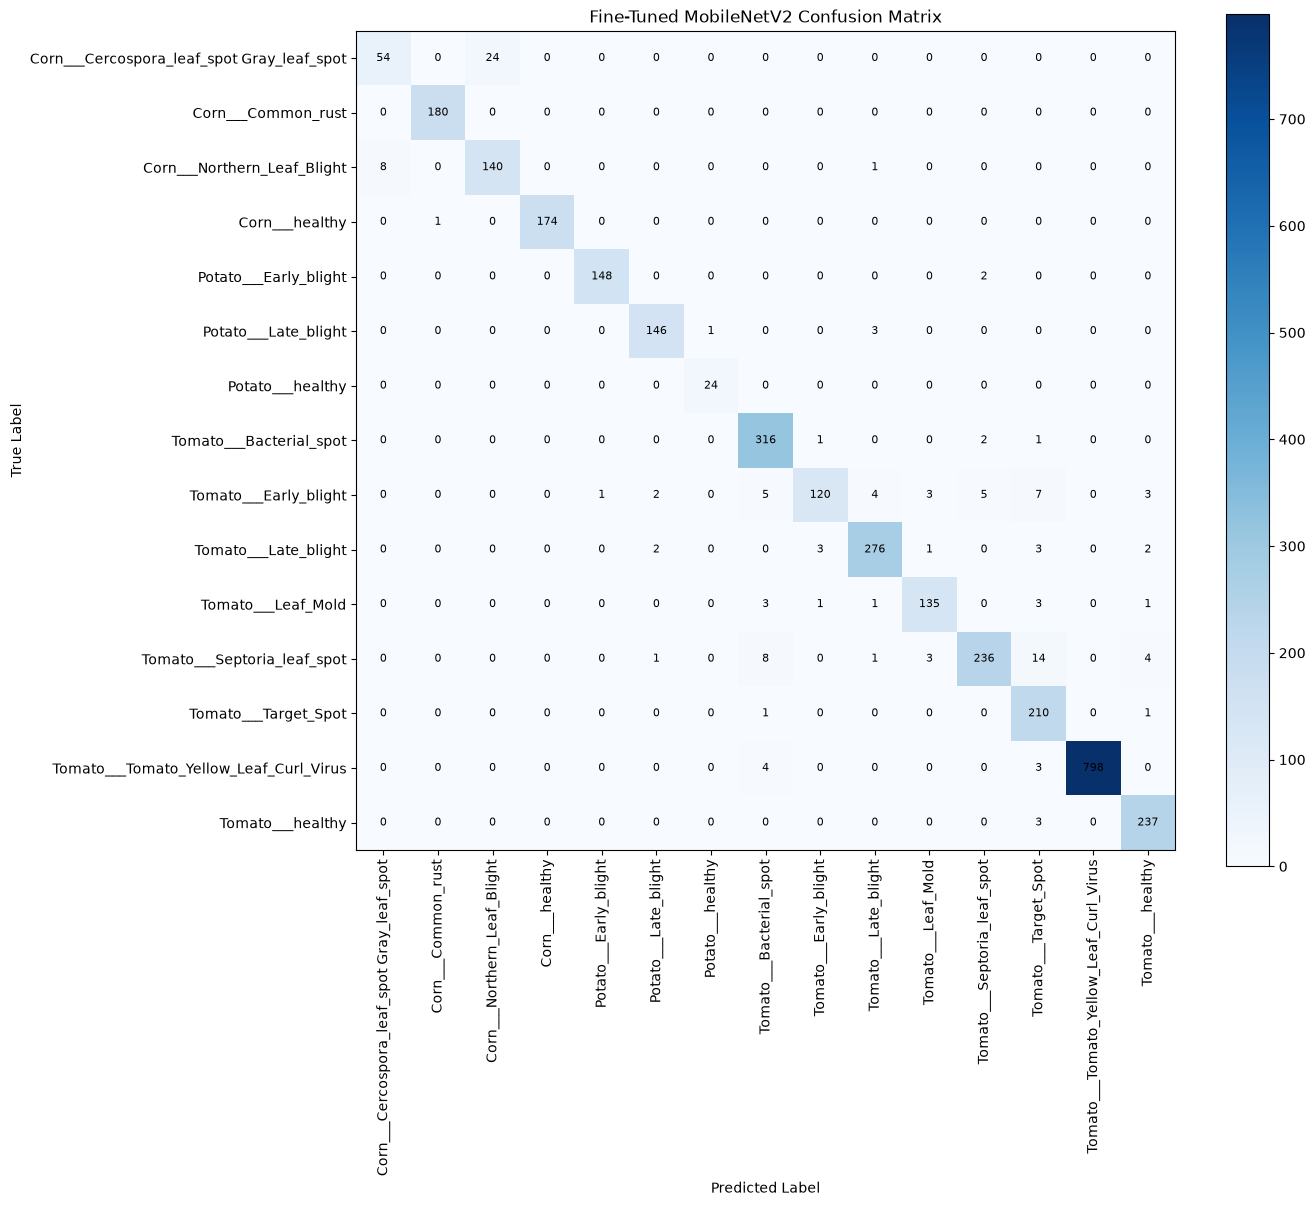

In [30]:
# Fine-tuned MobileNetV2 confusion matrix

fine_tuned_cm = confusion_matrix(
    transfer_y_true,
    fine_tuned_y_pred
)

plt.figure(figsize=(14, 12))

plt.imshow(fine_tuned_cm, cmap="Blues")
plt.colorbar()

plt.xticks(
    np.arange(len(test_class_names)),
    test_class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(test_class_names)),
    test_class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Fine-Tuned MobileNetV2 Confusion Matrix")

for i in range(len(test_class_names)):
    for j in range(len(test_class_names)):
        plt.text(
            j,
            i,
            fine_tuned_cm[i, j],
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

In [31]:
import json
from pathlib import Path

results = {
    "baseline_cnn": {
        "test_accuracy": 0.8727,
        "macro_precision": 0.8410,
        "macro_recall": 0.8297,
        "macro_f1": 0.8303
    },
    "mobilenetv2": {
        "test_accuracy": 0.9255,
        "macro_precision": 0.9051,
        "macro_recall": 0.9148,
        "macro_f1": 0.9082
    },
    "mobilenetv2_finetuned": {
        "test_accuracy": float(fine_tuned_test_accuracy),
        "macro_precision": float(fine_tuned_macro_precision),
        "macro_recall": float(fine_tuned_macro_recall),
        "macro_f1": float(fine_tuned_macro_f1)
    }
}

results_path = Path("../reports/final_model_results.json")
results_path.parent.mkdir(parents=True, exist_ok=True)

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("Final model results saved successfully.")
print(results_path)

Final model results saved successfully.
..\reports\final_model_results.json


In [32]:
# Check MobileNetV2 layers for Grad-CAM

for i, layer in enumerate(fine_tuned_model.layers):
    print(i, layer.name, layer.__class__.__name__)

0 input_layer_1 InputLayer
1 data_augmentation Sequential
2 mobilenetv2_1.00_224 Functional
3 global_average_pooling2d GlobalAveragePooling2D
4 dropout Dropout
5 dense Dense


In [33]:
# Inspect the MobileNetV2 backbone layers

mobilenet_backbone = fine_tuned_model.get_layer("mobilenetv2_1.00_224")

for i, layer in enumerate(mobilenet_backbone.layers[-20:]):
    print(
        len(mobilenet_backbone.layers) - 20 + i,
        layer.name,
        layer.__class__.__name__
    )

134 block_15_expand Conv2D
135 block_15_expand_BN BatchNormalization
136 block_15_expand_relu ReLU
137 block_15_depthwise DepthwiseConv2D
138 block_15_depthwise_BN BatchNormalization
139 block_15_depthwise_relu ReLU
140 block_15_project Conv2D
141 block_15_project_BN BatchNormalization
142 block_15_add Add
143 block_16_expand Conv2D
144 block_16_expand_BN BatchNormalization
145 block_16_expand_relu ReLU
146 block_16_depthwise DepthwiseConv2D
147 block_16_depthwise_BN BatchNormalization
148 block_16_depthwise_relu ReLU
149 block_16_project Conv2D
150 block_16_project_BN BatchNormalization
151 Conv_1 Conv2D
152 Conv_1_bn BatchNormalization
153 out_relu ReLU


In [40]:
# Fixed Grad-CAM function for nested MobileNetV2

def make_gradcam_heatmap(
    img_array,
    model,
    backbone,
    last_conv_layer_name,
    pred_index=None
):
    # Create a model from the MobileNetV2 backbone itself
    grad_model = tf.keras.models.Model(
        inputs=backbone.inputs,
        outputs=[
            backbone.get_layer(last_conv_layer_name).output,
            backbone.output
        ]
    )

    # Get the input after preprocessing/augmentation
    # The backbone receives the output of the data preprocessing layers
    backbone_input = model.get_layer("data_augmentation")(img_array)

    # MobileNetV2 preprocessing
    backbone_input = tf.keras.applications.mobilenet_v2.preprocess_input(
        backbone_input
    )

    with tf.GradientTape() as tape:

        conv_outputs, backbone_features = grad_model(
            backbone_input,
            training=False
        )

        # Pass backbone features through the classification head
        pooled_features = model.get_layer(
            "global_average_pooling2d"
        )(backbone_features)

        dropout_output = model.get_layer(
            "dropout"
        )(pooled_features, training=False)

        predictions = model.get_layer(
            "dense"
        )(dropout_output)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    # Calculate gradients
    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    # Average gradients spatially
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps by their importance
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # Keep positive activations
    heatmap = tf.maximum(heatmap, 0)

    # Normalize
    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy()

In [41]:
last_conv_layer_name = "out_relu"

print("Grad-CAM function created.")
print("Target layer:", last_conv_layer_name)

Grad-CAM function created.
Target layer: out_relu


In [42]:
# Select one image from the test dataset

import random
from pathlib import Path
from PIL import Image

# Get all test images
test_image_paths = list(Path("../data/test").rglob("*.jpg"))

# Select one random image
random.seed(42)
gradcam_image_path = random.choice(test_image_paths)

print("Selected image:")
print(gradcam_image_path)

Selected image:
..\data\test\Tomato___Tomato_Yellow_Leaf_Curl_Virus\image (1651).JPG


In [43]:
# Load and prepare the selected image

IMG_SIZE = (224, 224)

img = Image.open(gradcam_image_path).convert("RGB")

# Resize for the model
img_resized = img.resize(IMG_SIZE)

# Convert to NumPy array
img_array = np.array(img_resized, dtype=np.float32)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

print("Original image size:", img.size)
print("Model input shape:", img_array.shape)

Original image size: (256, 256)
Model input shape: (1, 224, 224, 3)


In [38]:
# Predict the selected image

prediction = fine_tuned_model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(prediction[0])
predicted_class = test_class_names[predicted_index]
confidence = prediction[0][predicted_index]

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.4f}")

Predicted class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 0.9997


In [44]:
# Generate Grad-CAM heatmap

heatmap = make_gradcam_heatmap(
    img_array,
    fine_tuned_model,
    mobilenet_backbone,
    last_conv_layer_name,
    pred_index=predicted_index
)

print("Grad-CAM heatmap generated.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), "to", heatmap.max())

Grad-CAM heatmap generated.
Heatmap shape: (7, 7)
Heatmap range: 0.0 to 1.0


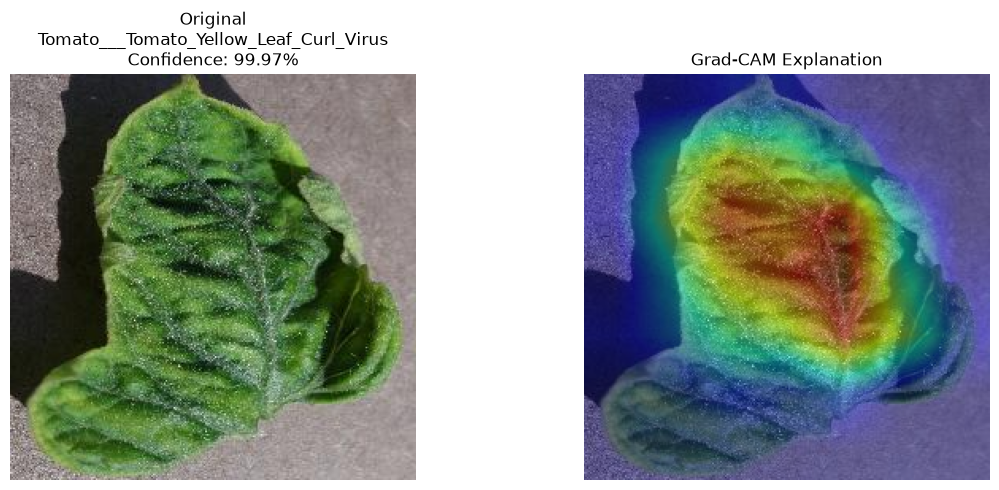

In [45]:
# Create Grad-CAM overlay

import cv2
import matplotlib.pyplot as plt

# Convert heatmap to 0-255
heatmap_uint8 = np.uint8(255 * heatmap)

# Resize heatmap to original image size
heatmap_resized = cv2.resize(
    heatmap_uint8,
    (img.width, img.height)
)

# Apply color map
heatmap_colored = cv2.applyColorMap(
    heatmap_resized,
    cv2.COLORMAP_JET
)

# Convert original PIL image to OpenCV format
original_image = np.array(img)

# Convert RGB -> BGR
original_image_bgr = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2BGR
)

# Create overlay
overlay = cv2.addWeighted(
    original_image_bgr,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Convert BGR -> RGB for Matplotlib
overlay_rgb = cv2.cvtColor(
    overlay,
    cv2.COLOR_BGR2RGB
)

# Display original and Grad-CAM
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(
    f"Original\n{predicted_class}\nConfidence: {confidence:.2%}"
)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay_rgb)
plt.title("Grad-CAM Explanation")
plt.axis("off")

plt.tight_layout()
plt.show()

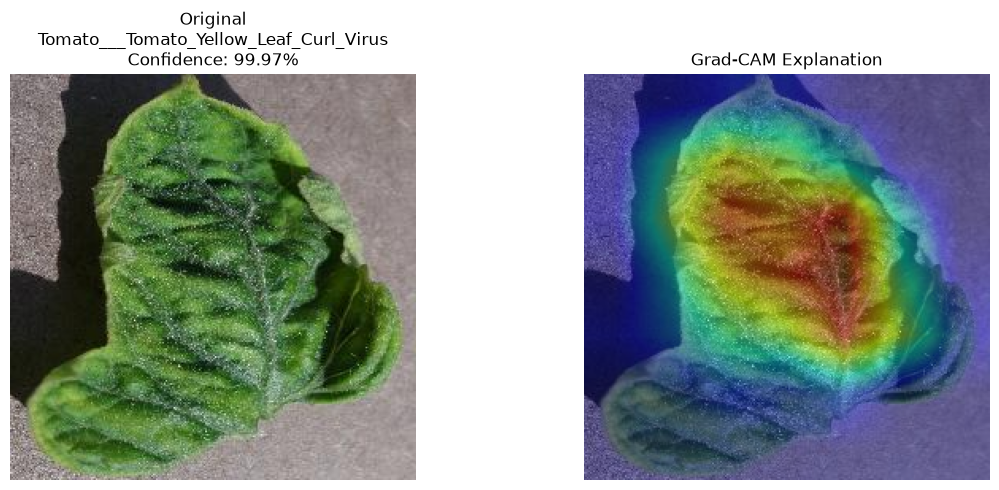

Grad-CAM figure saved successfully.
Saved to: ..\reports\gradcam\tomato_yellow_leaf_curl_virus_gradcam.png


In [46]:
# Save Grad-CAM visualization

from pathlib import Path

gradcam_output_dir = Path("../reports/gradcam")
gradcam_output_dir.mkdir(parents=True, exist_ok=True)

gradcam_output_path = gradcam_output_dir / "tomato_yellow_leaf_curl_virus_gradcam.png"

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(
    f"Original\n{predicted_class}\nConfidence: {confidence:.2%}"
)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay_rgb)
plt.title("Grad-CAM Explanation")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    gradcam_output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM figure saved successfully.")
print("Saved to:", gradcam_output_path)

In [47]:
import json

with open("../app/advisory.json", "r", encoding="utf-8") as f:
    advisory = json.load(f)

print("Advisory JSON loaded successfully.")
print("Number of disease/classes:", len(advisory) - 1)

for class_name in test_class_names:
    if class_name in advisory:
        print("✓", class_name)
    else:
        print("✗ MISSING:", class_name)

Advisory JSON loaded successfully.
Number of disease/classes: 15
✓ Corn___Cercospora_leaf_spot Gray_leaf_spot
✓ Corn___Common_rust
✓ Corn___Northern_Leaf_Blight
✓ Corn___healthy
✓ Potato___Early_blight
✓ Potato___Late_blight
✓ Potato___healthy
✓ Tomato___Bacterial_spot
✓ Tomato___Early_blight
✓ Tomato___Late_blight
✓ Tomato___Leaf_Mold
✓ Tomato___Septoria_leaf_spot
✓ Tomato___Target_Spot
✓ Tomato___Tomato_Yellow_Leaf_Curl_Virus
✓ Tomato___healthy


In [48]:
import json

with open("../app/classes.json", "r", encoding="utf-8") as f:
    classes = json.load(f)

print("Classes loaded successfully.")
print("Number of classes:", len(classes))

print("\nClass mapping:")
for i, class_name in enumerate(classes):
    print(f"{i}: {class_name}")

Classes loaded successfully.
Number of classes: 15

Class mapping:
0: Corn___Cercospora_leaf_spot Gray_leaf_spot
1: Corn___Common_rust
2: Corn___Northern_Leaf_Blight
3: Corn___healthy
4: Potato___Early_blight
5: Potato___Late_blight
6: Potato___healthy
7: Tomato___Bacterial_spot
8: Tomato___Early_blight
9: Tomato___Late_blight
10: Tomato___Leaf_Mold
11: Tomato___Septoria_leaf_spot
12: Tomato___Target_Spot
13: Tomato___Tomato_Yellow_Leaf_Curl_Virus
14: Tomato___healthy


In [49]:
# Convert the final fine-tuned model to TensorFlow Lite

import tensorflow as tf
from pathlib import Path

tflite_output_path = Path("../models/mobilenetv2_finetuned.tflite")

converter = tf.lite.TFLiteConverter.from_keras_model(
    fine_tuned_model
)

tflite_model = converter.convert()

with open(tflite_output_path, "wb") as f:
    f.write(tflite_model)

print("TensorFlow Lite model created successfully.")
print("Saved to:", tflite_output_path)
print(f"Model size: {tflite_output_path.stat().st_size / (1024 * 1024):.2f} MB")

INFO:tensorflow:Assets written to: C:\Users\madan\AppData\Local\Temp\tmp4o3wwp8q\assets


INFO:tensorflow:Assets written to: C:\Users\madan\AppData\Local\Temp\tmp4o3wwp8q\assets


Saved artifact at 'C:\Users\madan\AppData\Local\Temp\tmp4o3wwp8q'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 15), dtype=tf.float32, name=None)
Captures:
  2040312807504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312813072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312810960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312807888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312813648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312812496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312813264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312813456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312810768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2040312814608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  204

In [50]:
# Verify TensorFlow Lite model

import tensorflow as tf
import numpy as np
from PIL import Image

tflite_path = "../models/mobilenetv2_finetuned.tflite"

# Load TFLite interpreter
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("TFLite model loaded successfully.")
print("Input shape:", input_details[0]["shape"])
print("Input dtype:", input_details[0]["dtype"])
print("Output shape:", output_details[0]["shape"])
print("Output dtype:", output_details[0]["dtype"])

TFLite model loaded successfully.
Input shape: [  1 224 224   3]
Input dtype: <class 'numpy.float32'>
Output shape: [ 1 15]
Output dtype: <class 'numpy.float32'>


c:\Agro Care Ai\Agro Care AI\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [51]:
# Compare Keras and TFLite predictions

from PIL import Image
import numpy as np

# Use the same test image we used for Grad-CAM
test_image_path = "../data/test/Tomato___Tomato_Yellow_Leaf_Curl_Virus/image (1651).JPG"

# Load and preprocess image
img = Image.open(test_image_path).convert("RGB")
img = img.resize((224, 224))

image_array = np.array(img, dtype=np.float32)
image_batch = np.expand_dims(image_array, axis=0)

# --------------------------------------------------
# 1. KERAS PREDICTION
# --------------------------------------------------

keras_prediction = fine_tuned_model.predict(
    image_batch,
    verbose=0
)

keras_index = int(np.argmax(keras_prediction[0]))
keras_confidence = float(keras_prediction[0][keras_index])

# --------------------------------------------------
# 2. TFLITE PREDICTION
# --------------------------------------------------

interpreter.set_tensor(
    input_details[0]["index"],
    image_batch
)

interpreter.invoke()

tflite_prediction = interpreter.get_tensor(
    output_details[0]["index"]
)

tflite_index = int(np.argmax(tflite_prediction[0]))
tflite_confidence = float(tflite_prediction[0][tflite_index])

# --------------------------------------------------
# 3. DISPLAY RESULTS
# --------------------------------------------------

print("========== KERAS ==========")
print("Class index:", keras_index)
print("Class:", class_names[keras_index])
print("Confidence:", f"{keras_confidence * 100:.2f}%")

print()

print("========== TFLITE ==========")
print("Class index:", tflite_index)
print("Class:", class_names[tflite_index])
print("Confidence:", f"{tflite_confidence * 100:.2f}%")

print()

print("========== COMPARISON ==========")

if keras_index == tflite_index:
    print("✅ Prediction MATCHED")
else:
    print("❌ Prediction DID NOT MATCH")

print(
    "Confidence difference:",
    f"{abs(keras_confidence - tflite_confidence) * 100:.4f} percentage points"
)

========== KERAS ==========
Class index: 13
Class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 99.97%

========== TFLITE ==========
Class index: 13
Class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 99.97%

========== COMPARISON ==========
✅ Prediction MATCHED
Confidence difference: 0.0000 percentage points
